# 01 – Data Understanding
**Tetouan City Power Consumption – Deep Learning Coursework**

This notebook covers the Data Understanding phase (CRISP-DM):
1. Data collection
2. Data description
3. Exploratory Data Analysis (EDA)
4. Data quality verification

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Folder where all figures for the report are saved
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data Collection

In [2]:
df = pd.read_csv("../data/Tetuan_City_power_consumption.csv")

# Clean column names (Zone 2 and Zone 3 contain double spaces)
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()

# Shorter names for easier coding
df = df.rename(columns={
    "Wind Speed": "WindSpeed",
    "general diffuse flows": "GeneralDiffuseFlows",
    "diffuse flows": "DiffuseFlows",
    "Zone 1 Power Consumption": "Zone1",
    "Zone 2 Power Consumption": "Zone2",
    "Zone 3 Power Consumption": "Zone3",
})

df["DateTime"] = pd.to_datetime(df["DateTime"], format="%m/%d/%Y %H:%M")
df = df.set_index("DateTime").sort_index()

FEATURES = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]
TARGETS  = ["Zone1", "Zone2", "Zone3"]

print("Shape:", df.shape)
print("Period:", df.index.min(), "→", df.index.max())
df.head()

Shape: (52416, 8)
Period: 2017-01-01 00:00:00 → 2017-12-30 23:50:00


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,Zone1,Zone2,Zone3
DateTime,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [3]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 52416 entries, 2017-01-01 00:00:00 to 2017-12-30 23:50:00
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Temperature          52416 non-null  float64
 1   Humidity             52416 non-null  float64
 2   WindSpeed            52416 non-null  float64
 3   GeneralDiffuseFlows  52416 non-null  float64
 4   DiffuseFlows         52416 non-null  float64
 5   Zone1                52416 non-null  float64
 6   Zone2                52416 non-null  float64
 7   Zone3                52416 non-null  float64
dtypes: float64(8)
memory usage: 3.6 MB


## 2. Data Description

In [4]:
desc = df.describe().T
desc["median"]   = df.median()
desc["mode"]     = df.mode().iloc[0]
desc["variance"] = df.var()
desc["skewness"] = df.skew()
desc["kurtosis"] = df.kurt()
desc = desc[["count", "mean", "median", "mode", "std", "variance",
             "min", "25%", "75%", "max", "skewness", "kurtosis"]].round(2)

desc.to_csv(f"{FIG_DIR}/descriptive_statistics.csv")   # table for the report
desc

,count,mean,median,mode,std,variance,min,25%,75%,max,skewness,kurtosis
Temperature,52416.0,18.81,18.78,15.18,5.82,33.82,3.25,14.41,22.89,40.01,0.20,-0.30
Humidity,52416.0,68.26,69.86,85.90,15.55,241.84,11.34,58.31,81.40,94.80,-0.63,-0.12
WindSpeed,52416.0,1.96,0.09,0.08,2.35,5.52,0.05,0.08,4.92,6.48,0.46,-1.78
GeneralDiffuseFlows,52416.0,182.70,5.04,0.06,264.40,69907.87,0.00,0.06,319.60,1163.00,1.31,0.40
DiffuseFlows,52416.0,75.03,4.46,0.12,124.21,15428.36,0.01,0.12,101.00,936.00,2.46,7.00
Zone1,52416.0,32344.97,32265.92,34560.00,7130.56,50844922.48,13895.70,26310.67,37309.02,52204.40,0.23,-0.75
Zone2,52416.0,21042.51,20823.17,21600.00,5201.47,27055247.43,8560.08,16980.77,24713.72,37408.86,0.33,-0.44
Zone3,52416.0,17835.41,16415.12,17280.00,6622.17,43853070.60,5935.17,13129.33,21624.10,47598.33,1.02,1.09


## 3. Exploratory Data Analysis
### 3.1 Daily average consumption over the year

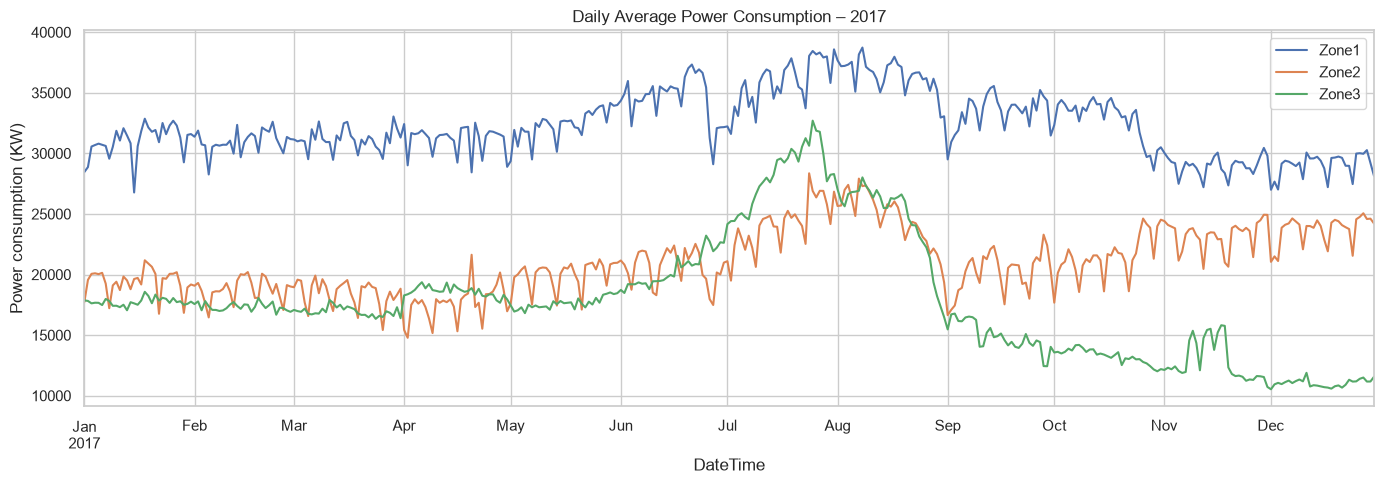

In [5]:
daily = df[TARGETS].resample("D").mean()
ax = daily.plot(figsize=(14, 5))
ax.set_title("Daily Average Power Consumption – 2017")
ax.set_ylabel("Power consumption (KW)")
save("01_daily_consumption")

### 3.2 Histograms (distribution of each variable)

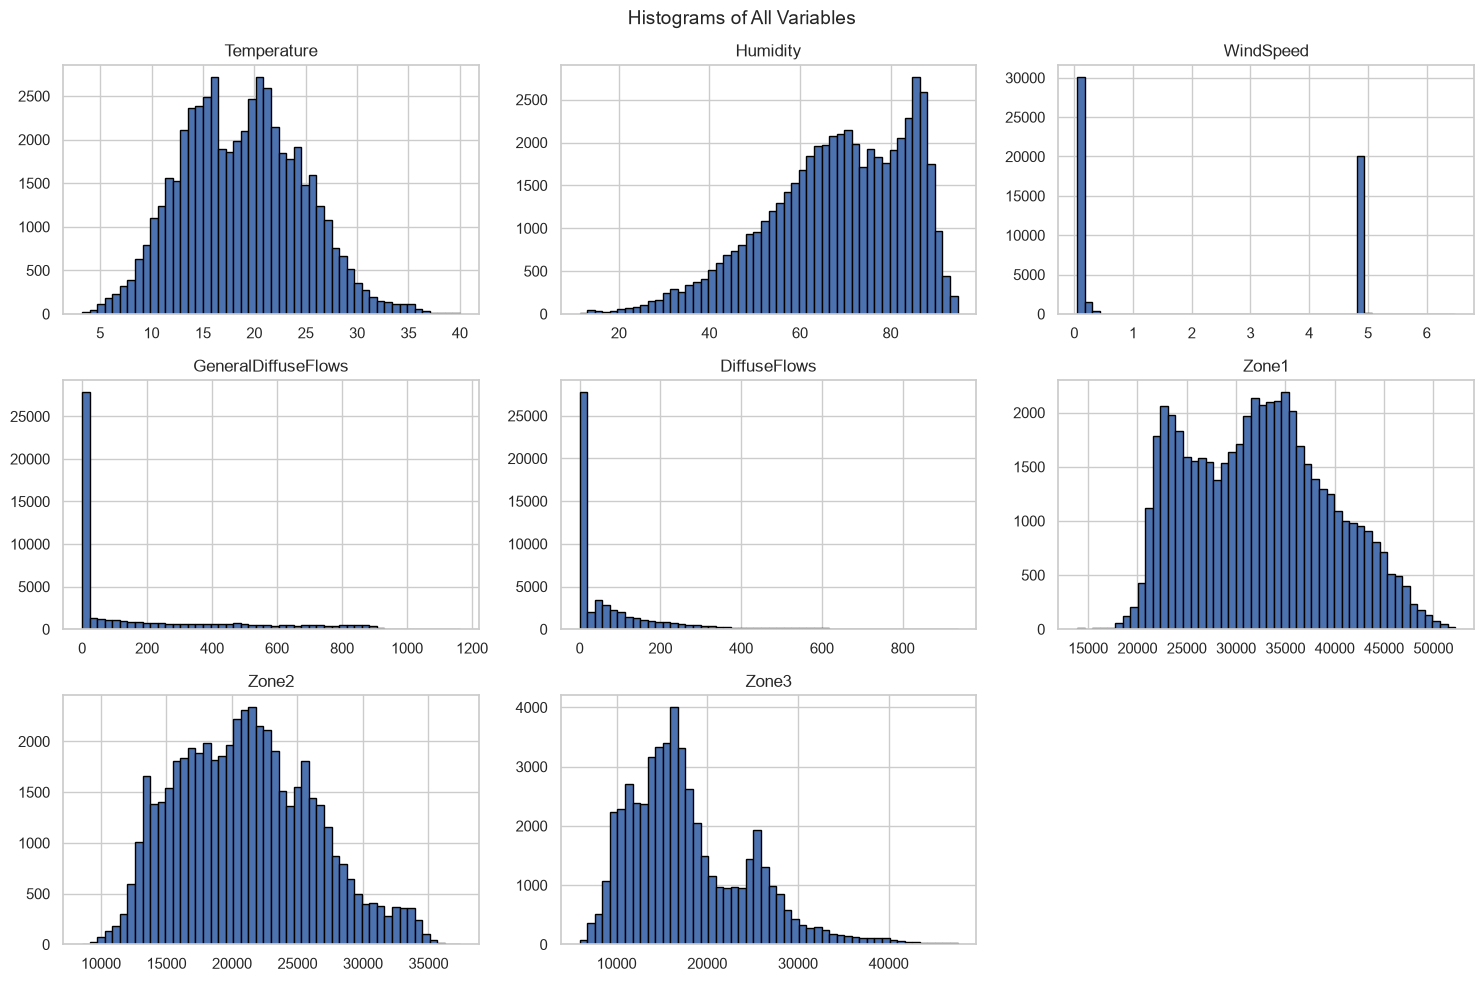

In [6]:
df.hist(bins=50, figsize=(15, 10), edgecolor="black")
plt.suptitle("Histograms of All Variables", fontsize=14)
save("02_histograms")

### 3.3 Boxplots (outlier detection)

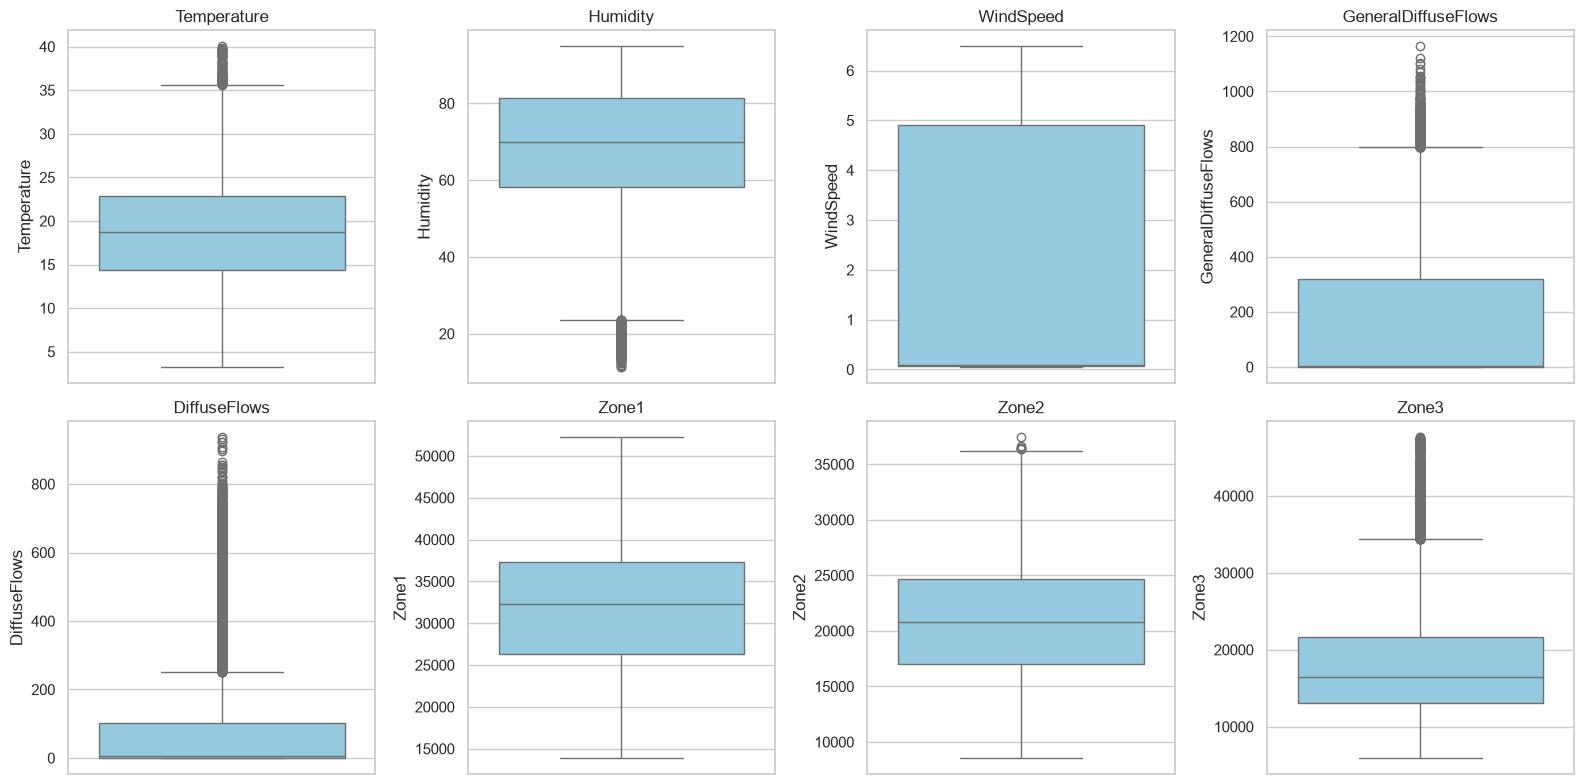

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, df.columns):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
save("03_boxplots")

### 3.4 Correlation matrix

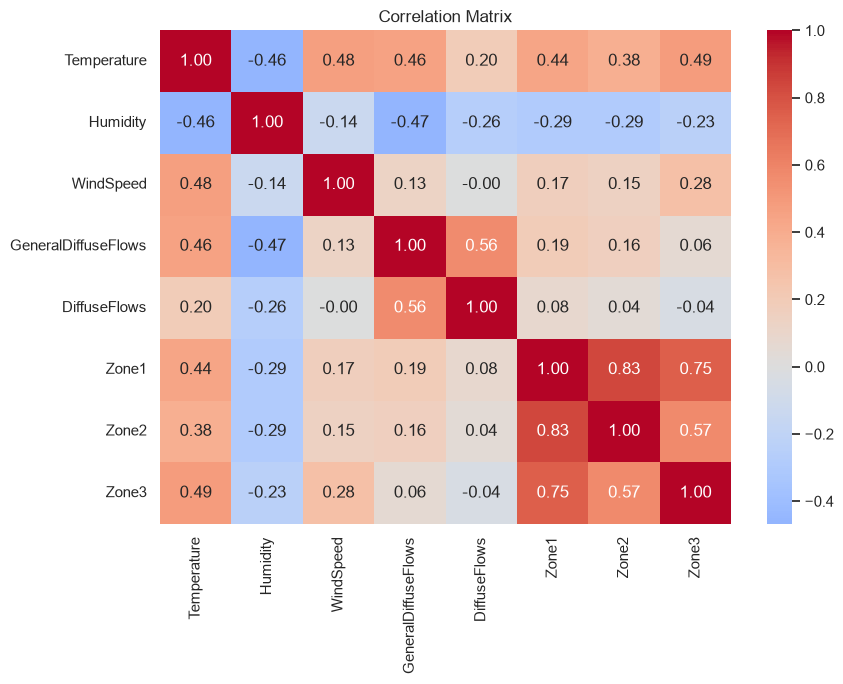

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
save("04_correlation_heatmap")

### 3.5 Scatter plots: Temperature vs Consumption

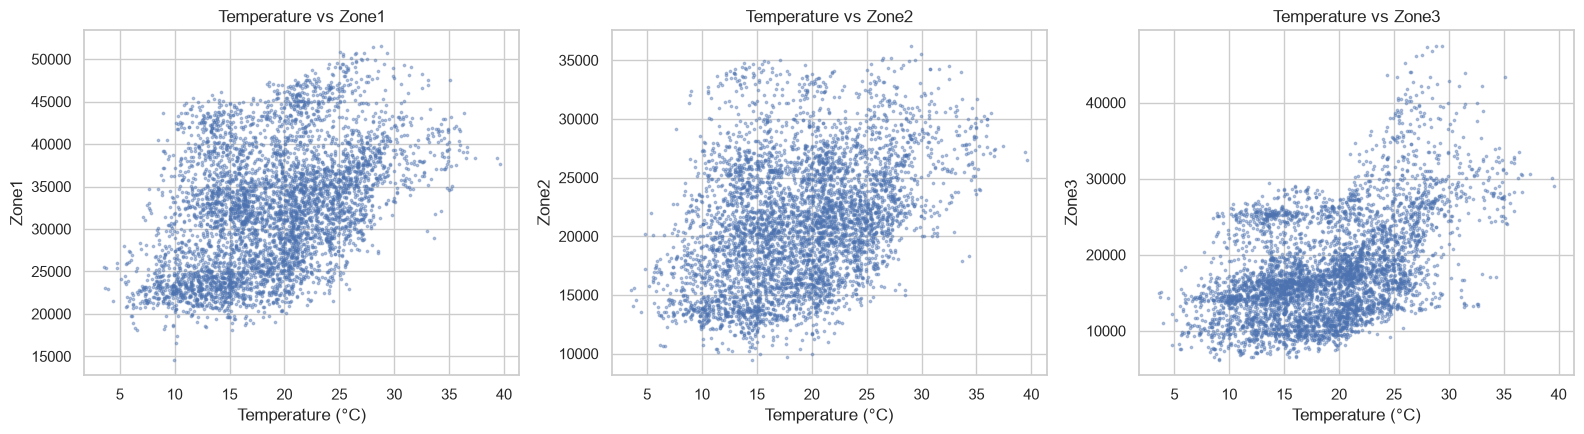

In [9]:
sample = df.sample(5000, random_state=42)   # sample so the plot is readable
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, z in zip(axes, TARGETS):
    ax.scatter(sample["Temperature"], sample[z], s=3, alpha=0.4)
    ax.set_xlabel("Temperature (°C)")
    ax.set_ylabel(z)
    ax.set_title(f"Temperature vs {z}")
save("05_scatter_temperature")

### 3.6 Daily profile: consumption by hour

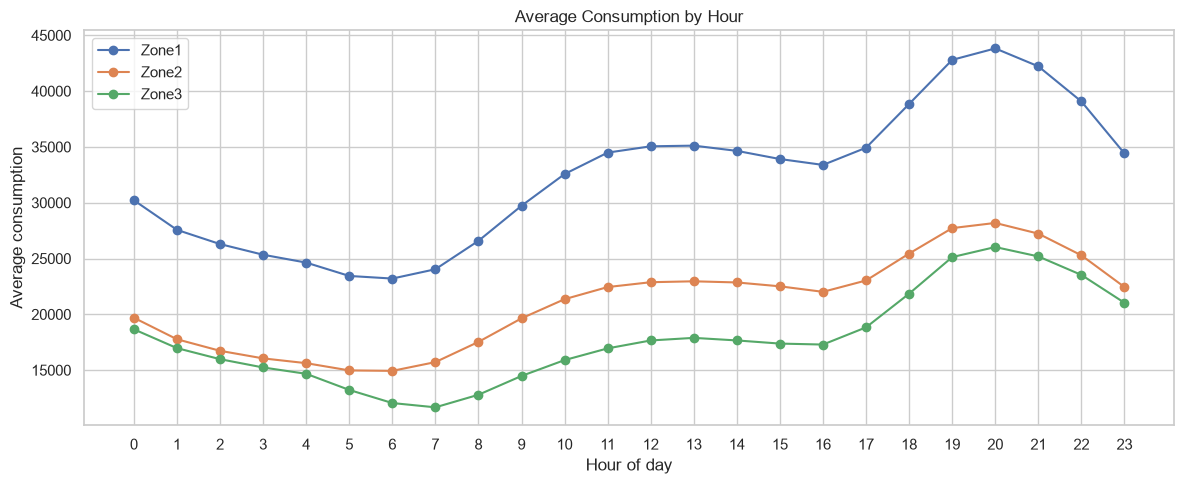

In [10]:
hourly = df.groupby(df.index.hour)[TARGETS].mean()
ax = hourly.plot(marker="o", figsize=(12, 5))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average consumption")
ax.set_title("Average Consumption by Hour")
ax.set_xticks(range(24))
save("06_hourly_profile")

### 3.7 Consumption by weekday and by month (bar charts)

C:\Users\olsas\AppData\Local\Temp\ipykernel_34584\1010643925.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekday = df.groupby(df.index.dayofweek)[TARGETS].mean()


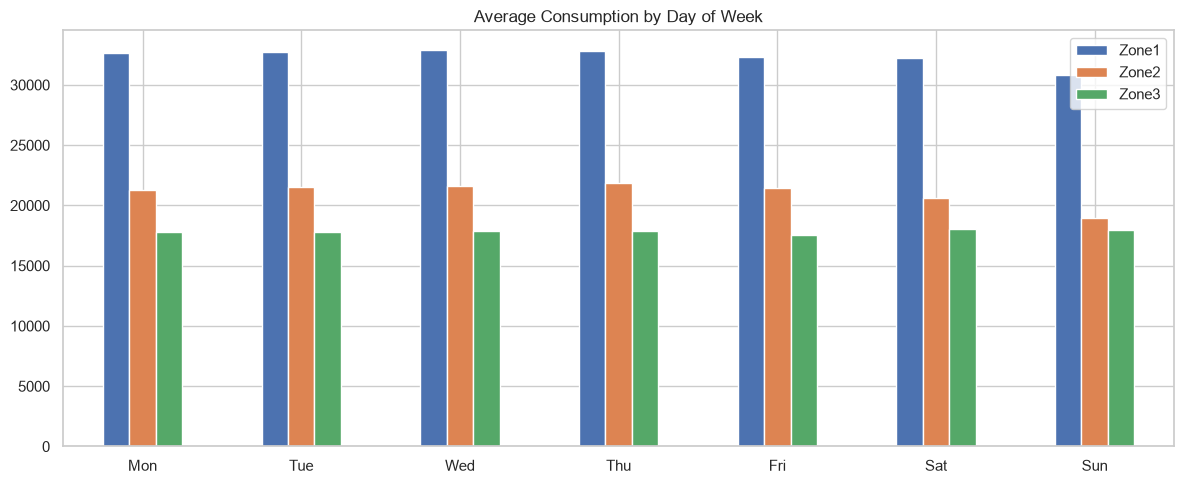

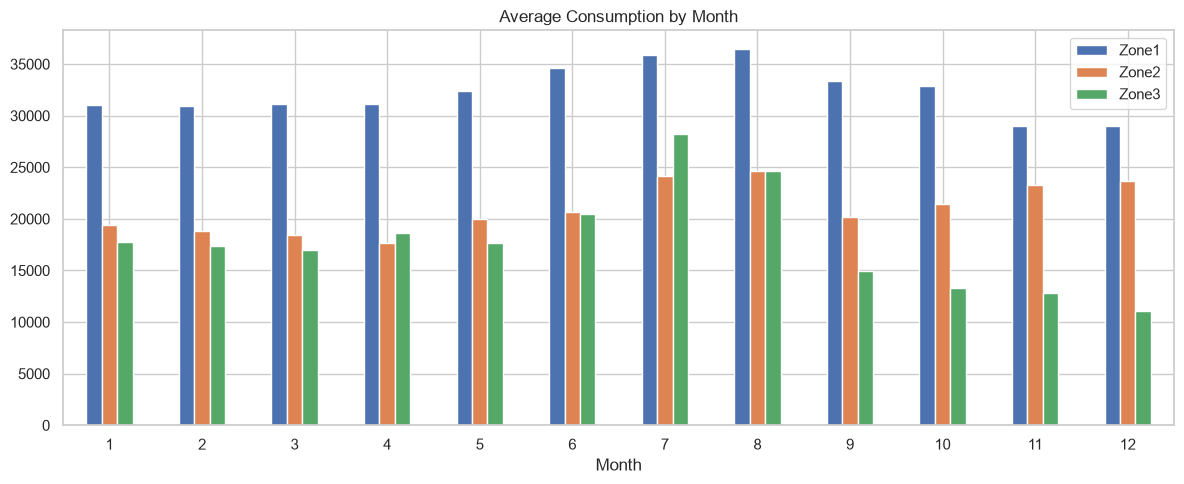

In [11]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = df.groupby(df.index.dayofweek)[TARGETS].mean()
weekday.index = days
weekday.plot(kind="bar", figsize=(12, 5), rot=0, title="Average Consumption by Day of Week")
save("07_weekday_bar")

monthly = df.groupby(df.index.month)[TARGETS].mean()
monthly.plot(kind="bar", figsize=(12, 5), rot=0, title="Average Consumption by Month")
plt.xlabel("Month")
save("08_monthly_bar")

### 3.8 Heatmap: hour × month (Zone 1)

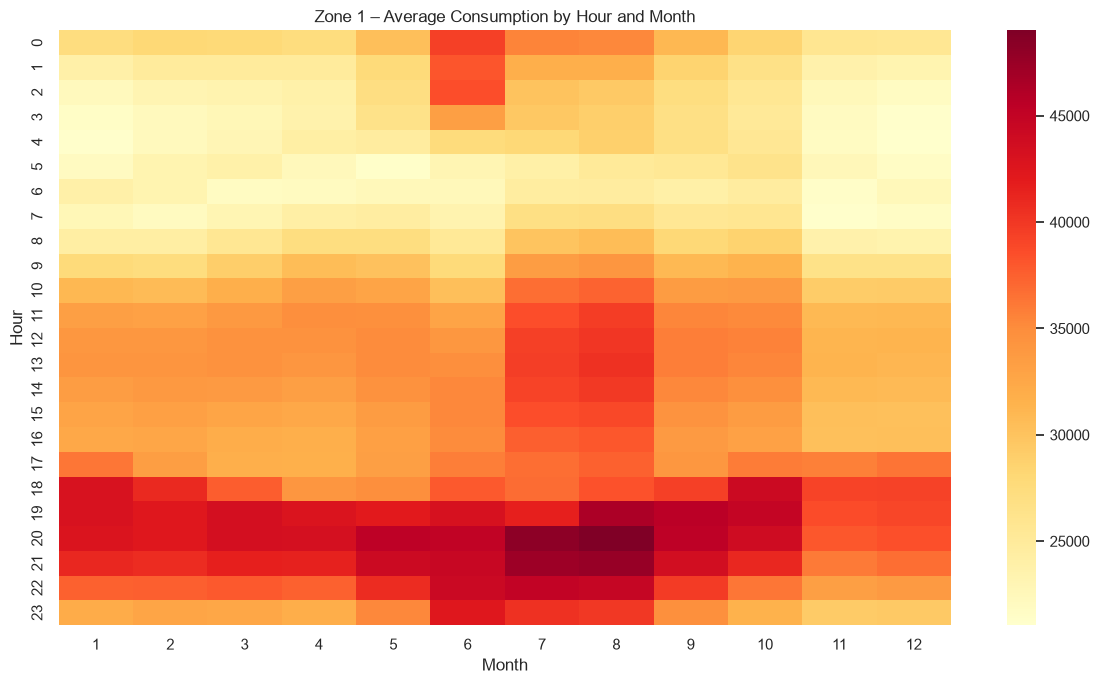

In [12]:
pivot = df.pivot_table(values="Zone1", index=df.index.hour, columns=df.index.month, aggfunc="mean")
plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd")
plt.xlabel("Month"); plt.ylabel("Hour")
plt.title("Zone 1 – Average Consumption by Hour and Month")
save("09_hour_month_heatmap")

## 4. Data Quality Verification
### 4.1 Missing values and duplicates

In [13]:
print("Missing values per column:\n", df.isnull().sum(), "\n")
print("Duplicated timestamps:", df.index.duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Missing values per column:
 Temperature            0
Humidity               0
WindSpeed              0
GeneralDiffuseFlows    0
DiffuseFlows           0
Zone1                  0
Zone2                  0
Zone3                  0
dtype: int64 

Duplicated timestamps: 0
Fully duplicated rows: 0


### 4.2 Time gaps (every row should be 10 minutes after the previous one)

In [14]:
gaps = df.index.to_series().diff().value_counts()
print(gaps)
expected = pd.date_range(df.index.min(), df.index.max(), freq="10min")
print("\nMissing timestamps in the series:", len(expected.difference(df.index)))

DateTime
0 days 00:10:00    52415
Name: count, dtype: int64

Missing timestamps in the series: 0


### 4.3 Outliers (IQR method)

In [15]:
Q1, Q3 = df.quantile(0.25), df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((df < Q1 - 1.5 * IQR) | (df > Q3 + 1.5 * IQR)).sum()
outlier_table = pd.DataFrame({"outliers": outliers,
                              "% of rows": (outliers / len(df) * 100).round(2)})
outlier_table

,outliers,% of rows
Temperature,142,0.27
Humidity,291,0.56
WindSpeed,0,0.00
GeneralDiffuseFlows,2315,4.42
DiffuseFlows,4571,8.72
Zone1,0,0.00
Zone2,7,0.01
Zone3,1191,2.27


### 4.4 Plausibility checks (are the values realistic?)

In [16]:
checks = {
    "Temperature outside [-10, 50] °C": ((df.Temperature < -10) | (df.Temperature > 50)).sum(),
    "Humidity outside [0, 100] %":      ((df.Humidity < 0) | (df.Humidity > 100)).sum(),
    "Negative wind speed":              (df.WindSpeed < 0).sum(),
    "Negative diffuse flows":           ((df.GeneralDiffuseFlows < 0) | (df.DiffuseFlows < 0)).sum(),
    "Consumption <= 0":                 (df[TARGETS] <= 0).sum().sum(),
}
pd.Series(checks, name="count")

Temperature outside [-10, 50] °C    0
Humidity outside [0, 100] %         0
Negative wind speed                 0
Negative diffuse flows              0
Consumption <= 0                    0
Name: count, dtype: int64

### 4.5 Diffuse flows at night
Solar radiation should be ~0 at night. This explains why the diffuse flow variables have a very
low median and many IQR "outliers". These are **not errors**: they are real daytime values.

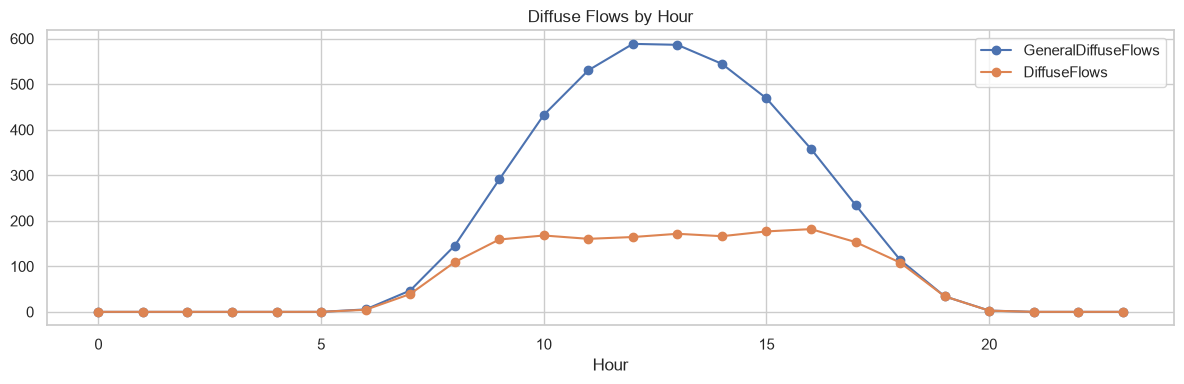

In [17]:
solar_by_hour = df.groupby(df.index.hour)[["GeneralDiffuseFlows", "DiffuseFlows"]].mean()
ax = solar_by_hour.plot(marker="o", figsize=(12, 4), title="Diffuse Flows by Hour")
ax.set_xlabel("Hour")
save("10_diffuse_by_hour")